# Chapitre 6 - Lissage par noyaux (1) : lisseurs unidimensionnels

Ce premier notebook de cours couvre les sections 6.1, 6.2 et 6.9 du livre.
L'idée directrice du chapitre est simple : pour estimer la fonction de régression
$f(x) = \mathbb E(Y \mid X = x)$ en un point $x_0$, on ajuste un modèle **très simple**
(une constante, une droite, une parabole) en n'utilisant **que les observations proches
de $x_0$**. On recommence pour chaque point cible : la fonction estimée $\hat f$ est la
collection de tous ces ajustements locaux.

La « proximité » est quantifiée par un **noyau** $K_\lambda(x_0, x_i)$ : un poids positif,
grand quand $x_i$ est proche de $x_0$ et qui décroît (souvent jusqu'à zéro) quand on
s'éloigne. Le paramètre $\lambda$ règle la largeur du voisinage.

> **Remarque.** Ces noyaux servent ici à **localiser**. Ils ne doivent pas être confondus
> avec les « noyaux reproduisants » des méthodes à noyaux (chapitres 5.8 et 12), qui
> calculent des produits scalaires dans un espace de grande dimension.

**Plan.**
1. Des k plus proches voisins à la moyenne pondérée de Nadaraya-Watson (fig. 6.1).
2. Trois noyaux classiques (fig. 6.2) et largeur métrique ou adaptative.
3. Régression linéaire locale et correction des effets de bord (fig. 6.3).
4. Noyau équivalent et biais (fig. 6.4), polynômes locaux (fig. 6.5), variance (fig. 6.6).
5. Choix de la largeur : compromis biais-variance, degrés de liberté, validation croisée,
   comparaison avec les splines de lissage (fig. 6.7).
6. Considérations de calcul.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch06_noyaux as nk
set_style()
GREEN, YELLOW, RED = COLORS[2], COLORS[3], COLORS[7]

## 1. Des k plus proches voisins à Nadaraya-Watson

### Les données simulées du livre

On reprend l'exemple de la figure 6.1 : $N = 100$ couples $(x_i, y_i)$ avec
$$
X \sim \mathcal U[0, 1], \qquad Y = \sin(4X) + \varepsilon, \qquad
\varepsilon \sim \mathcal N(0, 1/3).
$$
La vraie fonction de régression est donc $f(x) = \sin(4x)$, que nous connaissons, ce qui
permet de juger les estimateurs.

In [2]:
rng = np.random.RandomState(0)
N = 100
x = np.sort(rng.uniform(0, 1, N))
f_true = lambda t: np.sin(4 * t)
sigma = np.sqrt(1 / 3)
y = f_true(x) + sigma * rng.normal(size=N)
grid = np.linspace(0, 1, 401)
print("x dans [%.3f, %.3f], écart-type du bruit = %.3f" % (x.min(), x.max(), sigma))

x dans [0.005, 0.988], écart-type du bruit = 0.577


### La moyenne des k plus proches voisins

Au chapitre 2, on a estimé $\mathbb E(Y \mid X = x)$ par la moyenne des réponses des
$k$ points les plus proches (éq. (6.1) du livre) :
$$
\hat f(x) = \operatorname{Ave}\big(y_i \;\big|\; x_i \in N_k(x)\big),
$$
où $N_k(x)$ est l'ensemble des $k$ indices $i$ dont les $x_i$ sont les plus proches de $x$.
On « relâche » l'espérance conditionnelle (qui conditionne sur $X = x$ exactement) en
moyennant sur un **voisinage** de $x$.

**Défaut.** Quand $x_0$ se déplace vers la droite, le voisinage reste le même jusqu'à ce
qu'un nouveau point à droite devienne plus proche que le point le plus éloigné à gauche ;
celui-ci est alors **brutalement** remplacé. Chaque point entre ou sort avec un poids
$1/k$ d'un coup : $\hat f$ est une fonction **en escalier**, discontinue.

Le remède : donner aux points des poids qui **décroissent continûment** avec la distance.

### La moyenne pondérée de Nadaraya-Watson

L'estimateur de Nadaraya-Watson (éq. (6.2) du livre) est la moyenne pondérée
$$
\hat f(x_0) = \frac{\sum_{i=1}^N K_\lambda(x_0, x_i)\, y_i}{\sum_{i=1}^N K_\lambda(x_0, x_i)},
$$
avec par exemple le noyau quadratique d'Epanechnikov (éq. (6.3)-(6.4)) :
$$
K_\lambda(x_0, x) = D\!\left(\frac{|x - x_0|}{\lambda}\right), \qquad
D(t) = \begin{cases} \tfrac34 (1 - t^2) & \text{si } |t| \le 1,\\ 0 & \text{sinon.}\end{cases}
$$
Ici $\lambda$ est le **rayon** de la fenêtre : seuls les $x_i$ à distance $< \lambda$ de
$x_0$ comptent.

> **Intuition.** C'est un barycentre des $y_i$ : les poids normalisés
> $w_i(x_0) = K_\lambda(x_0, x_i) / \sum_j K_\lambda(x_0, x_j)$ sont positifs et de somme 1.
> Quand $x_0$ bouge, un point qui entre dans la fenêtre arrive avec un poids **nul**
> (car $D(1) = 0$) qui augmente progressivement : plus de saut.

### Figure 6.1

À gauche, le lisseur des 30 plus proches voisins ; à droite, Nadaraya-Watson avec le noyau
d'Epanechnikov et $\lambda = 0{,}2$. Au point $x_0 = 0{,}45$ on montre les observations
utilisées (cercles rouges) et, en jaune, la forme des poids.

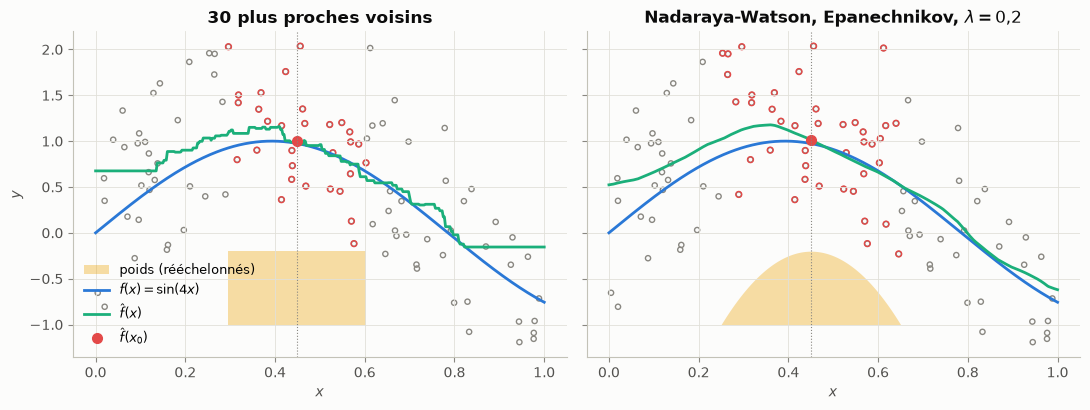

In [3]:
x0 = 0.45
fit_knn = nk.knn_mean(grid, x, y, 30)
fit_nw = nk.nadaraya_watson(grid, x, y, lam=0.2, kernel="epanechnikov")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, name in zip(axes, ["knn", "nw"]):
    if name == "knn":
        idx = np.argsort(np.abs(x - x0))[:30]
        w = np.zeros(N); w[idx] = 1.0
        fit, fx0, title = fit_knn, y[idx].mean(), "30 plus proches voisins"
        lo, hi = x[idx].min(), x[idx].max()
        ax.fill_between([lo, hi], -1.0, -1.0 + 0.8, color=YELLOW, alpha=0.35, lw=0,
                        label="poids (rééchelonnés)")
    else:
        w = nk.kernel_weights([x0], x, lam=0.2)[0]
        fx0, fit, title = np.sum(w * y) / w.sum(), fit_nw, "Nadaraya-Watson, Epanechnikov, $\\lambda=0{,}2$"
        tt = np.linspace(x0 - 0.2, x0 + 0.2, 100)
        ax.fill_between(tt, -1.0, -1.0 + 0.8 * nk.epanechnikov((tt - x0) / 0.2) / 0.75,
                        color=YELLOW, alpha=0.35, lw=0, label="poids (rééchelonnés)")
    ax.scatter(x, y, s=14, facecolors="none", edgecolors=GRAY)
    ax.scatter(x[w > 0], y[w > 0], s=18, facecolors="none", edgecolors=RED)
    ax.plot(grid, f_true(grid), color=BLUE, label="$f(x)=\\sin(4x)$")
    ax.plot(grid, fit, color=GREEN, label="$\\hat f(x)$")
    ax.plot([x0], [fx0], "o", color=RED, ms=7, label="$\\hat f(x_0)$")
    ax.axvline(x0, color=GRAY, lw=0.8, ls=":")
    ax.set_title(title); ax.set_xlabel("$x$")
axes[0].set_ylabel("$y$"); axes[0].legend(loc="lower left")
plt.tight_layout(); plt.show()

La courbe verte de gauche est cahoteuse (constante par morceaux), celle de droite est
continue et beaucoup plus lisse. L'exercice 6.1 étudie précisément la régularité de
$\hat f$ selon le noyau.

## 2. Noyaux et largeurs de fenêtre

### Largeur métrique ou adaptative

Plus généralement, on écrit (éq. (6.5) du livre)
$$
K_\lambda(x_0, x) = D\!\left(\frac{|x - x_0|}{h_\lambda(x_0)}\right),
$$
où $h_\lambda(x_0)$ est la **largeur** de la fenêtre en $x_0$ :
- **largeur métrique** : $h_\lambda(x_0) = \lambda$ constante ;
- **largeur des k-ppv** : $h_k(x_0) = |x_0 - x_{[k]}|$, distance de $x_0$ à son $k$-ième
  plus proche voisin. La fenêtre s'élargit là où les données sont rares.

> **À retenir.** Avec une largeur métrique, le **biais** reste à peu près constant mais
> la **variance** est inversement proportionnelle à la densité locale des $x_i$ (moins de
> points dans la fenêtre). Avec les k-ppv, c'est l'inverse : la variance est stable
> (toujours $k$ points) et le biais varie (la fenêtre s'élargit dans les zones creuses).

Illustration sur un plan d'expérience non uniforme (beaucoup de points à gauche, peu à
droite) : largeur de fenêtre $h(x_0)$ et nombre de points dans la fenêtre.

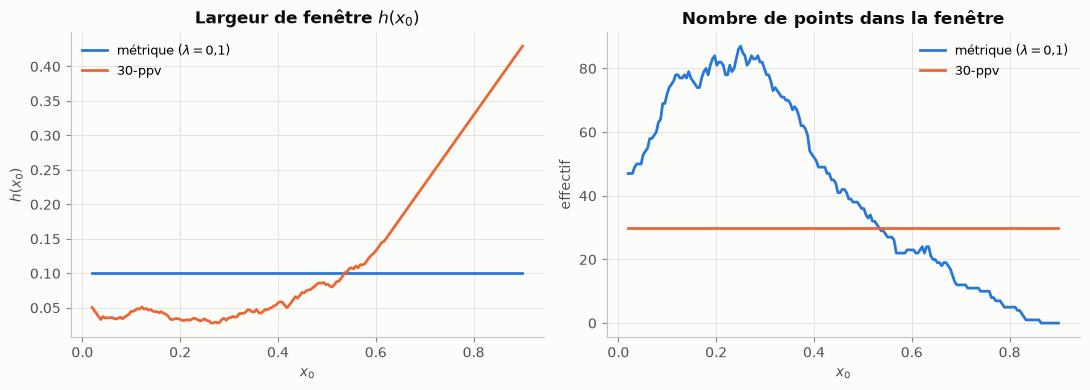

In [4]:
xs = np.sort(rng.beta(1.2, 3.0, 200))
t0 = np.linspace(0.02, 0.9, 200)
d = nk.distances(t0, xs)
h_knn = np.sort(d, axis=1)[:, 29]
count_metric = (d < 0.1).sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t0, np.full_like(t0, 0.1), label="métrique ($\\lambda = 0{,}1$)")
axes[0].plot(t0, h_knn, label="30-ppv")
axes[0].set_title("Largeur de fenêtre $h(x_0)$"); axes[0].set_xlabel("$x_0$")
axes[0].set_ylabel("$h(x_0)$"); axes[0].legend()
axes[1].plot(t0, count_metric, label="métrique ($\\lambda = 0{,}1$)")
axes[1].plot(t0, np.full_like(t0, 30), label="30-ppv")
axes[1].set_title("Nombre de points dans la fenêtre"); axes[1].set_xlabel("$x_0$")
axes[1].set_ylabel("effectif"); axes[1].legend()
plt.tight_layout(); plt.show()

### Trois noyaux classiques (figure 6.2)

- **Epanechnikov** : $D(t) = \tfrac34(1-t^2)\,\mathbf 1_{|t|\le1}$ ; support compact,
  continu mais **non dérivable** en $t = \pm1$ (pente $\mp 3/2$ d'un côté, 0 de l'autre).
- **Tri-cube** (éq. (6.6)) : $D(t) = (1-|t|^3)^3\,\mathbf 1_{|t|\le 1}$ ; plus plat au
  sommet, et ses dérivées première et seconde s'annulent en $\pm 1$ : il est $C^2$.
- **Gaussien** : $D(t) = \varphi(t) = e^{-t^2/2}/\sqrt{2\pi}$ ; indéfiniment dérivable
  mais à support **infini** ; $\lambda$ joue alors le rôle d'un écart-type.

Pour la figure, chaque noyau est normalisé pour être d'intégrale 1. Pour le tri-cube,
$$
\int_{-1}^1 (1-|t|^3)^3\,dt = 2\int_0^1 (1 - 3t^3 + 3t^6 - t^9)\,dt
= 2\left(1 - \tfrac34 + \tfrac37 - \tfrac1{10}\right) = \tfrac{81}{70},
$$
d'où le facteur $70/81$.

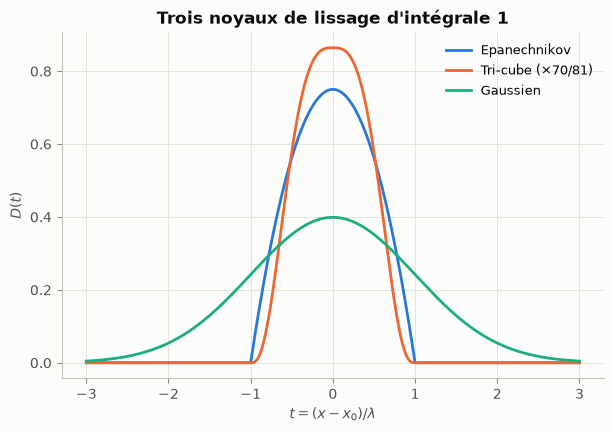

In [5]:
t = np.linspace(-3, 3, 601)
plt.figure(figsize=(7, 4.5))
plt.plot(t, nk.epanechnikov(t), label="Epanechnikov")
plt.plot(t, nk.tricube(t) * 70 / 81, label="Tri-cube (×70/81)")
plt.plot(t, nk.gaussian(t), label="Gaussien")
plt.title("Trois noyaux de lissage d'intégrale 1")
plt.xlabel("$t = (x - x_0)/\\lambda$"); plt.ylabel("$D(t)$")
plt.legend(); plt.show()

Vérification numérique des intégrales :

In [6]:
from scipy import integrate
for name, fn, c in [("Epanechnikov", nk.epanechnikov, 1), ("Tri-cube", nk.tricube, 70 / 81),
                    ("Gaussien", nk.gaussian, 1)]:
    val = integrate.quad(lambda s: c * fn(s), -8, 8, points=[-1, 1])[0]
    print("%-13s intégrale = %.6f" % (name, val))

Epanechnikov  intégrale = 1.000000
Tri-cube      intégrale = 1.000000
Gaussien      intégrale = 1.000000


**Autres détails pratiques** (résumé du livre) :
- **ex æquo** dans les $x_i$ : on peut remplacer les points confondus par leur moyenne,
  affectée d'un poids égal à leur nombre ;
- **poids d'observation** $w_i$ : on les multiplie simplement par les poids du noyau ;
- **bords** : une fenêtre métrique contient moins de points au bord, une fenêtre de k-ppv
  s'y élargit ; dans les deux cas l'estimation se dégrade (section suivante).
- un noyau à support compact est indispensable avec les fenêtres de k-ppv (sinon la
  « taille » $k$ n'a pas de sens).

## 3. Régression linéaire locale

### Le problème des bords

Près de $x_0 = 0$, tous les points de la fenêtre sont **à droite** de $x_0$. Si $f$ est
croissante à cet endroit, leur moyenne est plus grande que $f(x_0)$ : la moyenne pondérée
est biaisée vers le haut, même si les poids décroissent. C'est l'asymétrie de la fenêtre
qui crée ce biais.

### Définition (éq. (6.7) du livre)

En chaque point cible $x_0$, on résout un problème de **moindres carrés pondérés**
$$
\min_{\alpha(x_0),\,\beta(x_0)} \sum_{i=1}^N K_\lambda(x_0, x_i)
\big[y_i - \alpha(x_0) - \beta(x_0)\, x_i\big]^2,
$$
puis on pose $\hat f(x_0) = \hat\alpha(x_0) + \hat\beta(x_0)\, x_0$. On ajuste toute une
droite, mais on ne l'utilise **qu'en $x_0$**.

### Forme explicite (éq. (6.8)-(6.9))

Notons $b(x)^T = (1, x)$, $\mathbf B$ la matrice $N\times 2$ de lignes $b(x_i)^T$ et
$\mathbf W(x_0) = \operatorname{diag}\big(K_\lambda(x_0, x_i)\big)$. Le critère s'écrit
$(\mathbf y - \mathbf B\theta)^T \mathbf W(x_0) (\mathbf y - \mathbf B\theta)$ avec
$\theta = (\alpha, \beta)^T$.

- On annule le gradient en $\theta$ : $-2\mathbf B^T\mathbf W(x_0)(\mathbf y - \mathbf B\theta) = 0$.
- Si $\mathbf B^T\mathbf W(x_0)\mathbf B$ est inversible (au moins deux $x_i$ distincts de
  poids non nul), $\hat\theta = (\mathbf B^T\mathbf W\mathbf B)^{-1}\mathbf B^T\mathbf W\mathbf y$.
- On évalue la droite en $x_0$ :
$$
\hat f(x_0) = b(x_0)^T(\mathbf B^T\mathbf W(x_0)\mathbf B)^{-1}\mathbf B^T\mathbf W(x_0)\,\mathbf y
= \sum_{i=1}^N l_i(x_0)\, y_i .
$$

> **À retenir.** L'estimateur est **linéaire en les $y_i$** : les poids $l_i(x_0)$ ne
> dépendent que des $x_i$, de $x_0$ et du noyau. On appelle $l(x_0) = (l_i(x_0))_i$ le
> **noyau équivalent**. Nadaraya-Watson est le cas particulier « degré 0 » où
> $l_i(x_0) = K_\lambda(x_0,x_i)/\sum_j K_\lambda(x_0,x_j)$.

> **Remarque (implémentation).** Dans `esl/ch06_noyaux.py`, on centre la base en $x_0$ :
> $b(x) = (1, x - x_0)$. Le modèle ajusté est le même, et $\hat f(x_0)$ est alors
> simplement le coefficient constant. C'est numériquement plus stable et se généralise
> à tout degré et toute dimension.

Vérification : formule matricielle (6.8) écrite telle quelle contre la fonction du module.

In [7]:
x0 = 0.3
w = nk.kernel_weights([x0], x, lam=0.2, kernel="tricube")[0]
B = np.column_stack([np.ones(N), x])
W = np.diag(w)
f_formula = np.array([1, x0]) @ np.linalg.solve(B.T @ W @ B, B.T @ W @ y)
f_module = nk.local_regression([x0], x, y, lam=0.2, degree=1, kernel="tricube")[0]
print("formule (6.8) : %.10f   module : %.10f" % (f_formula, f_module))

formule (6.8) : 1.1806970591   module : 1.1806970591


### Figure 6.3 : Nadaraya-Watson contre linéaire local au bord

Même noyau d'Epanechnikov ($\lambda = 0{,}2$) ; au point $x_0$ proche de 0 la moyenne
pondérée est tirée vers le haut, alors que la droite locale « suit la pente ».

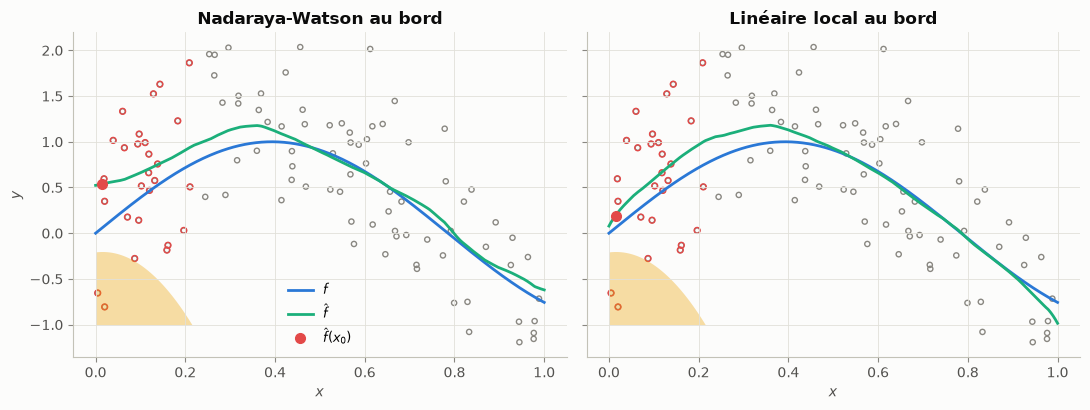

In [8]:
x0 = x.min() + 0.01
fit_ll = nk.local_regression(grid, x, y, lam=0.2, degree=1, kernel="epanechnikov")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, fit, title in [(axes[0], fit_nw, "Nadaraya-Watson au bord"),
                       (axes[1], fit_ll, "Linéaire local au bord")]:
    w = nk.kernel_weights([x0], x, lam=0.2)[0]
    ax.scatter(x, y, s=14, facecolors="none", edgecolors=GRAY)
    ax.scatter(x[w > 0], y[w > 0], s=18, facecolors="none", edgecolors=RED)
    tt = np.linspace(0, x0 + 0.2, 100)
    ax.fill_between(tt, -1.0, -1.0 + 0.8 * nk.epanechnikov((tt - x0) / 0.2) / 0.75,
                    color=YELLOW, alpha=0.35, lw=0)
    ax.plot(grid, f_true(grid), color=BLUE, label="$f$")
    ax.plot(grid, fit, color=GREEN, label="$\\hat f$")
    fx0 = np.interp(x0, grid, fit)
    ax.plot([x0], [fx0], "o", color=RED, ms=7, label="$\\hat f(x_0)$")
    ax.set_title(title); ax.set_xlabel("$x$")
axes[0].set_ylabel("$y$"); axes[0].legend(loc="lower center")
plt.tight_layout(); plt.show()

Sur un seul échantillon, la différence peut être masquée par le bruit. Pour voir le
**biais** $\mathbb E\hat f(x_0) - f(x_0)$, on fait une simulation de Monte-Carlo :
300 échantillons indépendants, et on moyenne les ajustements.

In [ ]:
R = 300
G = np.linspace(0, 1, 101)
fits = {0: np.zeros((R, G.size)), 1: np.zeros((R, G.size))}
L0 = None
for r in range(R):
    xr = np.sort(rng.uniform(0, 1, N))
    yr = f_true(xr) + sigma * rng.normal(size=N)
    for deg in (0, 1):
        fits[deg][r] = nk.local_regression(G, xr, yr, lam=0.2, degree=deg, kernel="epanechnikov")

plt.figure(figsize=(7, 4.5))
plt.plot(G, fits[0].mean(0) - f_true(G), label="Nadaraya-Watson")
plt.plot(G, fits[1].mean(0) - f_true(G), label="linéaire local")
plt.axhline(0, color=GRAY, lw=0.8)
plt.title("Biais estimé par Monte-Carlo ($\\lambda = 0{,}2$, 300 répétitions)")
plt.xlabel("$x_0$"); plt.ylabel("$\\mathbb{E}\\hat f(x_0) - f(x_0)$")
plt.legend(); plt.show()

Le biais de Nadaraya-Watson est énorme aux deux bords (où $f$ est croissante à gauche et
décroissante à droite) ; la régression linéaire locale le supprime « au premier ordre ».
À l'intérieur, les deux souffrent d'un biais lié à la **courbure** de $f$ (près des
extrema de $\sin(4x)$ en $x = \pi/8 \approx 0{,}39$ et $x = 3\pi/8 \approx 1{,}18$).

## 4. Noyau équivalent, biais et polynômes locaux

### Figure 6.4 : le noyau équivalent

On trace les poids $l_i(x_0)$ de la régression linéaire locale (tri-cube, $\lambda=0{,}2$)
en fonction de $x_i$, au bord et à l'intérieur, et on les compare aux poids de
Nadaraya-Watson.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, x0, title in [(axes[0], 0.03, "au bord ($x_0 = 0{,}03$)"),
                      (axes[1], 0.6, "à l'intérieur ($x_0 = 0{,}6$)")]:
    l_ll = nk.local_weights_matrix([x0], x, lam=0.2, degree=1, kernel="tricube")[0]
    l_nw = nk.local_weights_matrix([x0], x, lam=0.2, degree=0, kernel="tricube")[0]
    ax.fill_between(x, 0, l_nw, color=YELLOW, alpha=0.4, lw=0, label="Nadaraya-Watson")
    ax.plot(x, l_ll, "o", color=GREEN, ms=4, label="linéaire local")
    ax.axhline(0, color=GRAY, lw=0.8); ax.axvline(x0, color=RED, lw=1, ls=":")
    ax.set_title("Noyau équivalent " + title); ax.set_xlabel("$x_i$")
axes[0].set_ylabel("$l_i(x_0)$"); axes[0].legend()
plt.tight_layout(); plt.show()